# Geo-Wiki 2015: dataset coverage and African class balance

Purpose: explore the source structure, whole-site coverage, and class balance,
with **all African sites retained and no class filtering**. Inputs are the complete
CSV and Natural Earth boundaries acquired in the [download notebook](0.02-tp-geowiki-2015-download.ipynb).
The source is [Zenodo 14871660, v1](https://zenodo.org/records/14871660), CC BY 4.0.

This adapts the whole-cluster aggregation and Africa rule from the supplied
`0.03-tp-geowiki-2015-sites.ipynb`, and the two class-balance denominators from
`0.06-tp-geowiki-africa-class-balance.ipynb`. Its population is all source sites
whose mean annotation centre falls in Africa, rather than a historical inventory
of successfully exported TIFFs. The earlier 44,644-site total is a comparison,
not a hard-coded target or a validation assertion.

Outputs: reusable global site/class summaries under `data/interim/geowiki/14871660/`,
Africa selection and balance CSVs under `runs/tables/geowiki/14871660/`, and static
figures under `runs/figures/geowiki/14871660/`. Originals are read only.


```mermaid
flowchart TD
    A["Complete Geo-Wiki CSV; chunk size"] --> B["Inspect columns and aggregate whole sites across chunks"]
    B --> C["data/interim/geowiki/14871660/: site counts and class labels"]
    C --> D["Mean WGS84 annotation centres"]
    E["Natural Earth countries: CONTINENT = Africa"] --> F["Select centres covered by Africa"]
    D --> F
    F --> G["All African sites; all classes"]
    G --> H["Pixel share and site-presence summaries"]
    G --> I["Static site coverage map"]
    G --> L["Seeded random 100-row site; read source coordinates"]
    L --> M["Local metric projection; 100 x 100 m class plot"]
    M --> N["runs/figures/geowiki/14871660/random_site.png"]
    H --> J["runs/tables/geowiki/14871660/ and class-balance figure"]
    I --> K["runs/figures/geowiki/14871660/africa_coverage.png"]
```

Mermaid rendering depends on the notebook viewer.


## 1. Environment and settings

Use the installed project package for paths. WGS84 (EPSG:4326) is retained for
continent membership and the longitude/latitude display; no distances or areas
are measured for those operations. The single-site view uses a local azimuthal
equidistant projection centred on the selected site, with coordinates in meters.

| Parameter | Default | Unit | Meaning / why this default |
| --- | --- | --- | --- |
| CHUNK_ROWS | 250000 | annotation rows | Bound CSV memory use without truncating the input. |
| REBUILD_SUMMARY | False | boolean | Reuse an expensive global summary after the first complete scan. |
| SITE_RANDOM_SEED | 42 | dimensionless | Reproduce the random example; change for another site. |
| URBAN_CLASS_ID | 3028 | class ID | Highlight urban/built-up in the supplied class-balance comparison. |

The input release and boundary paths are fixed by the download notebook. If you
deliberately replace that release, review both notebooks and rebuild the summaries.
Rerun from the settings cell after changing settings. There is no preview limit,
minimum class proportion, site subset, or class-selection switch.


In [1]:
import sys
from time import perf_counter

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Rectangle
import pandas as pd
import shapely
from IPython.display import display

from tomer_peled_mgi_thesis.config import (
    RAW_DATA_DIR, EXTERNAL_DATA_DIR, INTERIM_DATA_DIR,
    TABLES_DIR, FIGURES_DIR, ensure_output_dir,
)

CHUNK_ROWS = 250_000
REBUILD_SUMMARY = False
URBAN_CLASS_ID = 3028
SITE_RANDOM_SEED = 42

source_path = RAW_DATA_DIR / "geowiki/14871660/final_reference_data.csv"
boundary_path = EXTERNAL_DATA_DIR / "natural_earth/countries.geojson"
summary_dir = ensure_output_dir(INTERIM_DATA_DIR / "geowiki/14871660")
table_dir = ensure_output_dir(TABLES_DIR / "geowiki/14871660")
figure_dir = ensure_output_dir(FIGURES_DIR / "geowiki/14871660")
sites_path = summary_dir / "site_summary.csv"
labels_path = summary_dir / "classes.csv"
print(f"Python: {sys.executable}")


Python: c:\Users\tomer\OneDrive\Home\MGI\Thesis\tomer_peled_mgi_thesis\.pixi\envs\default\python.exe


## 2. Inspect the annotation contract

Inspect a small sample before the expensive full scan. Keep IDs separate from
coordinates and labels. `timestamp` records when an interpreter annotated the
sample; `reference_year` records the land-cover reference year.
Zenodo describes nominal clusters of 100 pixels at 10 m resolution. We count
annotation rows as labelled pixels, following the supplied notebooks; the site
size distribution below exposes departures from the nominal 100-row cluster.
This workflow does not reconstruct native Sentinel-2 grids or collapse duplicate
annotations into cells.


In [2]:
columns = ["sampleid", "class_id", "class_name", "reference_year", "center_x", "center_y"]
preview = pd.read_csv(source_path, nrows=5)
display(preview.drop(columns=[column for column in preview if column.startswith("Unnamed:")]))
display(pd.DataFrame({"column": preview.columns, "sample_dtype": preview.dtypes.astype(str).to_numpy()}))


,validation_id,submission_item_id,sampleid,timestamp,class_id,class_name,reference_year,center_x,center_y
0,907283,15220761,998380,2017-11-25 17:27:19.545618,3027,crops,2015,76.875177,27.500164
1,907283,15220766,998380,2017-11-25 17:27:19.545618,3024,tree,2015,76.875378,27.500071
2,907506,15242996,1000543,2017-11-26 15:56:21.282651,3026,grassland,2015,44.913569,-25.095318
3,907724,15264870,1010739,2017-11-28 12:17:54.465365,3026,grassland,2015,18.749929,13.124710
4,907724,15264900,1010739,2017-11-28 12:17:54.465365,3026,grassland,2015,18.749930,13.124619


,column,sample_dtype
0,Unnamed: 0,int64
1,validation_id,int64
2,submission_item_id,int64
3,sampleid,int64
4,timestamp,object
5,class_id,int64
6,class_name,object
7,reference_year,int64
8,center_x,float64
9,center_y,float64


## 3. Summarize complete sites

Scan the entire CSV in chunks. Sum coordinates and class counts by `sampleid`
across chunk boundaries before deriving the mean centre, so a site split between
chunks is counted once. Keep every observed class ID and its source label.
Cache only the small summary and dictionary, rather than staging a second 2 GB
table in SQLite. Progress shows annotation rows processed, not an inferred site count.

On a fresh scan, reject missing labels/coordinates, non-2015 reference years,
out-of-range WGS84 coordinates, or conflicting class names: those would bias
the geographic selection or class denominator. Cached project summaries already
have this contract and are loaded directly.


In [3]:
if sites_path.exists() and labels_path.exists() and not REBUILD_SUMMARY:
    sites = pd.read_csv(sites_path)
    class_labels = pd.read_csv(labels_path)
    print(f"Loaded summary for {len(sites):,} complete source sites")
else:
    totals = pd.DataFrame()
    label_parts = []
    rows_read = 0
    started = perf_counter()
    for number, chunk in enumerate(pd.read_csv(source_path, usecols=columns, chunksize=CHUNK_ROWS), 1):
        if chunk[columns].isna().any().any():
            raise ValueError("Missing site, class, year, or coordinate values; review before summarizing")
        if not chunk.reference_year.eq(2015).all():
            raise ValueError("Unexpected reference year in the 2015 release")
        if not (chunk.center_x.between(-180, 180) & chunk.center_y.between(-90, 90)).all():
            raise ValueError("Coordinates outside WGS84 longitude/latitude ranges")

        coordinates = chunk.groupby("sampleid", sort=False).agg(
            annotations=("class_id", "size"),
            longitude_sum=("center_x", "sum"), latitude_sum=("center_y", "sum"),
        )
        counts = pd.crosstab(chunk.sampleid, chunk.class_id)
        counts.columns = [f"class_{class_id}" for class_id in counts.columns]
        partial = coordinates.join(counts).fillna(0)
        totals = totals.add(partial, fill_value=0)
        label_parts.append(chunk[["class_id", "class_name"]].drop_duplicates())
        rows_read += len(chunk)
        print(f"Chunk {number}: {rows_read:,} annotations; {perf_counter() - started:.1f}s elapsed", flush=True)

    class_labels = pd.concat(label_parts).drop_duplicates().sort_values("class_id")
    if class_labels.class_id.duplicated().any():
        raise ValueError("A class ID has conflicting names; review the source labels")
    sites = totals.fillna(0).rename_axis("sampleid").reset_index()
    sites["longitude"] = sites.pop("longitude_sum") / sites.annotations
    sites["latitude"] = sites.pop("latitude_sum") / sites.annotations
    count_columns = ["sampleid", "annotations"] + [column for column in sites if column.startswith("class_")]
    sites[count_columns] = sites[count_columns].astype("int64")
    sites.to_csv(sites_path, index=False)
    class_labels.to_csv(labels_path, index=False)
    print(f"Saved summary: {len(sites):,} sites from {rows_read:,} annotations")

class_columns = [f"class_{class_id}" for class_id in class_labels.class_id]
display(sites[["sampleid", "annotations", "longitude", "latitude"]].head())
display(class_labels.reset_index(drop=True))


Loaded summary for 165,696 complete source sites


,sampleid,annotations,longitude,latitude
0,993222,100,103.220235,3.766779
1,993223,100,43.690444,14.609569
2,993224,100,45.312456,32.812552
3,993225,100,39.375010,25.937806
4,993226,100,57.187805,27.500173


,class_id,class_name
0,3024,tree
1,3025,shrub
2,3026,grassland
3,3027,crops
4,3028,urban/built-up
5,3029,bare
6,3030,burnt
7,3031,water
8,3032,snow and ice
9,3033,fallow/shifting cultivation


## 4. Examine global coverage and site sizes

These are descriptive summaries, not filters. Report sites that depart from
100 annotation rows without silently dropping them. Class statistics remain
annotation-weighted; repeated or incomplete clusters require further investigation
before treating those counts as unique physical cells or training targets.


In [4]:
overview = pd.Series({
    "global_sites": len(sites), "annotation_rows": int(sites.annotations.sum()),
    "observed_classes": len(class_labels), "sites_with_100_rows": int(sites.annotations.eq(100).sum()),
    "sites_with_other_row_counts": int(sites.annotations.ne(100).sum()),
}, name="count")
display(overview.to_frame())
display(sites.annotations.describe().to_frame("annotation_rows_per_site"))


,count
global_sites,165696
annotation_rows,16569600
observed_classes,13
sites_with_100_rows,165696
sites_with_other_row_counts,0


,annotation_rows_per_site
count,165696.0
mean,100.0
std,0.0
min,100.0
25%,100.0
50%,100.0
75%,100.0
max,100.0


## 5. Select all African sites

Africa means Natural Earth countries with `CONTINENT = Africa`. Retain a site
when its mean supplied WGS84 annotation centre is **inside or on** the combined
boundary (`covers`). This matches the supplied notebook's whole-site rule; all
annotations in each selected site remain in the balance denominator.
Mean centres are sufficient for these small clusters but are not geodesic centroids.
The coarse boundary may miss small islands and coastal sites and is a present-day
reference, not a reconstruction of 2015 political boundaries.


In [5]:
countries = gpd.read_file(boundary_path)
if countries.crs is None:
    raise ValueError("Boundary CRS is missing; do not infer it from coordinate ranges")
countries = countries.to_crs("EPSG:4326")
africa = countries.loc[countries.CONTINENT.eq("Africa"), ["ADMIN", "geometry"]].copy()
africa_geometry = africa.geometry.union_all()
shapely.prepare(africa_geometry)
centres = shapely.points(sites.longitude.to_numpy(), sites.latitude.to_numpy())
selection = sites.assign(in_africa=shapely.covers(africa_geometry, centres))
africa_sites = selection.loc[selection.in_africa].copy()
if africa_sites.empty:
    raise ValueError("No sites selected in Africa; inspect the boundary and coordinate fields")
selection[["sampleid", "annotations", "longitude", "latitude", "in_africa"]].to_csv(
    table_dir / "site_selection.csv", index=False,
)
print(f"{len(sites):,} global sites → {len(africa_sites):,} African sites, no class filtering")
print(f"African labelled annotation rows: {africa_sites.annotations.sum():,}")


165,696 global sites → 44,644 African sites, no class filtering
African labelled annotation rows: 4,464,400


## 5a. Visualisation - African coverage

A static overview shows the continent selection and spatial gaps using every
selected site, without marker sampling. It is a longitude/latitude display,
not an area-preserving map or a measure of sample density. Natural Earth supplies
the context; a contemporary imagery basemap is unnecessary for this question.


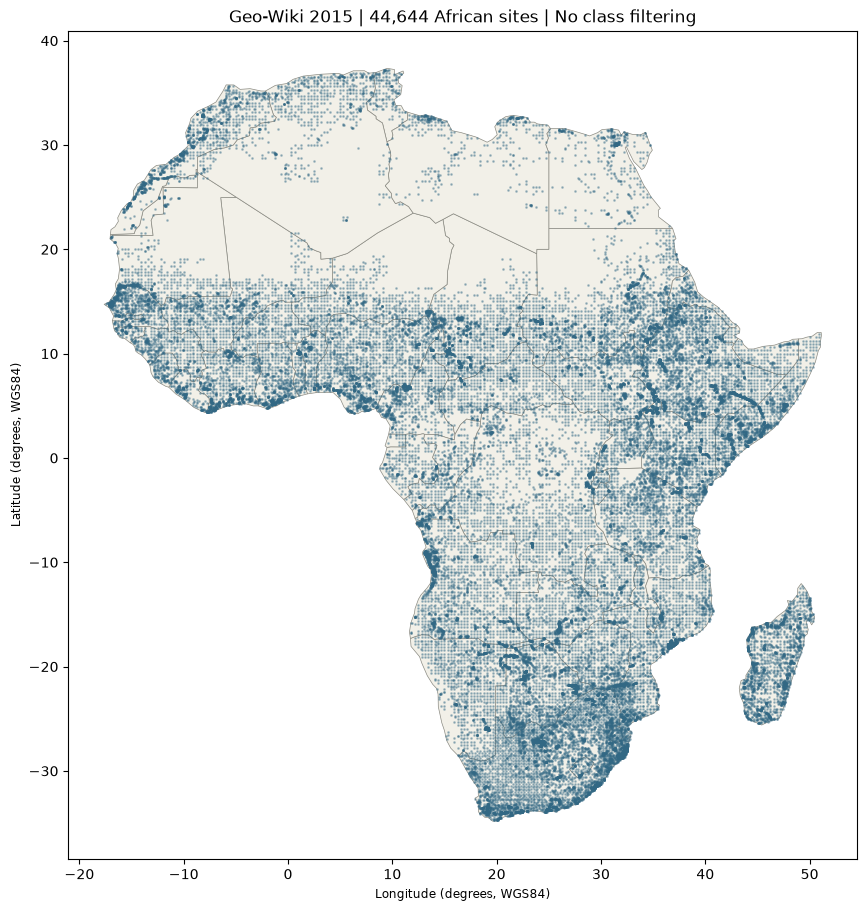

In [6]:
fig, ax = plt.subplots(figsize=(9, 9), layout="constrained")
africa.plot(ax=ax, facecolor="#f2f0e8", edgecolor="#8b8b83", linewidth=0.5)
ax.scatter(africa_sites.longitude, africa_sites.latitude, s=1, alpha=0.35, color="#326884", rasterized=True)
ax.set_title(f"Geo-Wiki 2015 | {len(africa_sites):,} African sites | No class filtering")
ax.set_xlabel("Longitude (degrees, WGS84)")
ax.set_ylabel("Latitude (degrees, WGS84)")
ax.set_aspect("equal")
fig.savefig(figure_dir / "africa_coverage.png", dpi=150)
plt.show()


## 5b. Inspect one random nominal 100 x 100 m site

Select one African site with 100 annotation rows using `SITE_RANDOM_SEED`.
This restriction applies only to the example; all sites remain in the class-balance
analysis. Read all matching rows across the full CSV because sites span chunks.
Transform WGS84 centres to a local azimuthal equidistant CRS in meters.


In [7]:
example_site = africa_sites.loc[africa_sites.annotations.eq(100)].sample(
    n=1, random_state=SITE_RANDOM_SEED,
).iloc[0]
example_id = int(example_site.sampleid)
example_parts = []
for chunk in pd.read_csv(
    source_path, usecols=["sampleid", "class_id", "center_x", "center_y"],
    chunksize=CHUNK_ROWS,
):
    matching = chunk.loc[chunk.sampleid.eq(example_id)]
    if not matching.empty:
        example_parts.append(matching)
example_rows = pd.concat(example_parts, ignore_index=True)
local_crs = (
    f"+proj=aeqd +lat_0={example_site.latitude} +lon_0={example_site.longitude} "
    "+datum=WGS84 +units=m +no_defs"
)
example_points = gpd.GeoDataFrame(
    example_rows,
    geometry=gpd.points_from_xy(example_rows.center_x, example_rows.center_y),
    crs="EPSG:4326",
).to_crs(local_crs)
print(f"Selected site {example_id}: {len(example_points)} annotation rows")


Selected site 1151194: 100 annotation rows


## 5c. Visualisation - Random site classes in meters

A static 100 x 100 m window shows the supplied centres as nominal 10 m squares,
with a legend for classes present. Axes are east/north offsets from the mean site
centre. Squares are a schematic annotation display, not a reconstructed native
Sentinel-2 grid; nominal pixel edges can extend slightly outside the window.


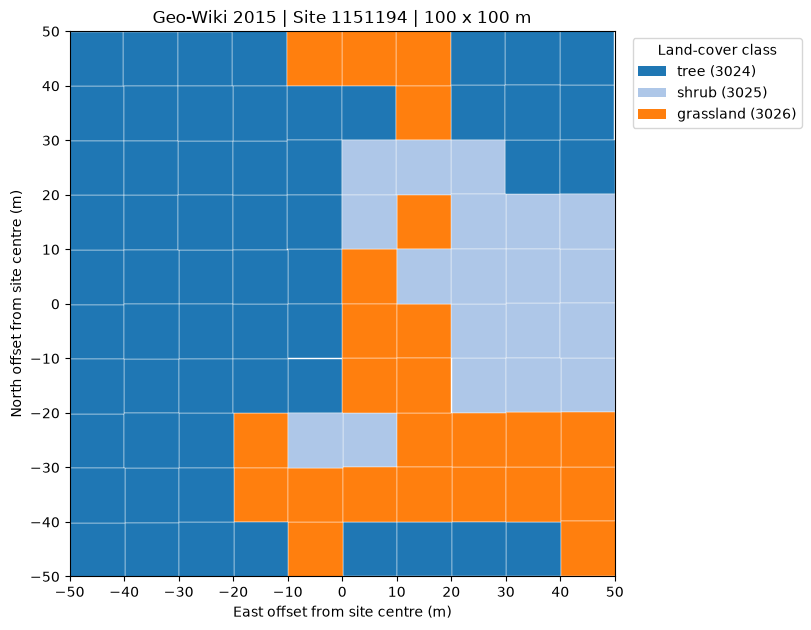

In [8]:
class_colors = {
    class_id: plt.get_cmap("tab20")(index % 20)
    for index, class_id in enumerate(class_labels.class_id)
}
fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
patches = [Rectangle((point.x - 5, point.y - 5), 10, 10)
           for point in example_points.geometry]
ax.add_collection(PatchCollection(
    patches, facecolors=[class_colors[c] for c in example_points.class_id],
    edgecolors="white", linewidths=0.3,
))
present_classes = class_labels.loc[class_labels.class_id.isin(example_points.class_id)]
ax.legend(
    handles=[Patch(facecolor=class_colors[row.class_id],
                   label=f"{row.class_name} ({row.class_id})")
             for row in present_classes.itertuples()],
    title="Land-cover class", loc="upper left", bbox_to_anchor=(1.02, 1),
)
ax.set(xlim=(-50, 50), ylim=(-50, 50),
       xlabel="East offset from site centre (m)",
       ylabel="North offset from site centre (m)",
       title=f"Geo-Wiki 2015 | Site {example_id} | 100 x 100 m")
ax.set_aspect("equal")
ax.set_xticks(range(-50, 51, 10))
ax.set_yticks(range(-50, 51, 10))
fig.savefig(figure_dir / "random_site.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Compare pixel share and site presence

Keep every globally observed class, including classes with zero African counts.
**Pixel share** divides class annotation rows by all African annotation rows.
**Site presence** divides sites with at least one annotation of the class by all
African sites. Sites can contain several classes, so presence percentages may
sum above 100%; pixel shares should sum to 100%.
Neither quantity is a continental land-area estimate. No TIFF reads or export
success conditions enter these denominators.


In [7]:
counts = africa_sites[class_columns]
class_balance = pd.DataFrame({
    "class_id": class_labels.class_id.to_numpy(),
    "labelled_pixels": counts.sum().to_numpy(),
    "sites_containing_class": counts.gt(0).sum().to_numpy(),
}).merge(class_labels, on="class_id", how="left", validate="one_to_one")
if class_balance.labelled_pixels.sum() != africa_sites.annotations.sum():
    raise ValueError("Class counts omit annotations and would bias the pixel-share denominator")
class_balance["pixel_percent"] = 100 * class_balance.labelled_pixels / africa_sites.annotations.sum()
class_balance["site_presence_percent"] = 100 * class_balance.sites_containing_class / len(africa_sites)
class_balance = class_balance.sort_values("labelled_pixels", ascending=False).reset_index(drop=True)
class_balance = class_balance[["class_id", "class_name", "labelled_pixels", "pixel_percent",
                               "sites_containing_class", "site_presence_percent"]]
class_balance.to_csv(table_dir / "africa_class_balance.csv", index=False)
display(class_balance.round({"pixel_percent": 4, "site_presence_percent": 4}))


,class_id,class_name,labelled_pixels,pixel_percent,sites_containing_class,site_presence_percent
0,3026,grassland,1627287,36.4503,30794,68.9768
1,3025,shrub,910629,20.3976,29916,67.0101
2,3024,tree,744163,16.6688,23691,53.0665
3,3027,crops,476012,10.6624,7797,17.4648
4,3029,bare,343748,7.6998,9194,20.5940
5,3471,wetland (herbaceous),113483,2.5420,1373,3.0754
6,3031,water,112827,2.5273,1762,3.9468
7,3028,urban/built-up,49968,1.1193,2600,5.8239
8,3034,Not sure,41512,0.9298,445,0.9968
9,3033,fallow/shifting cultivation,33740,0.7558,1035,2.3183


## 6a. Visualisation - Class balance

Two static bar panels use the same class order so the denominators are easy to
compare. Urban/built-up is highlighted, and small nonzero percentages are labelled
even where their bars are too short to see. Exact counts remain in the table.


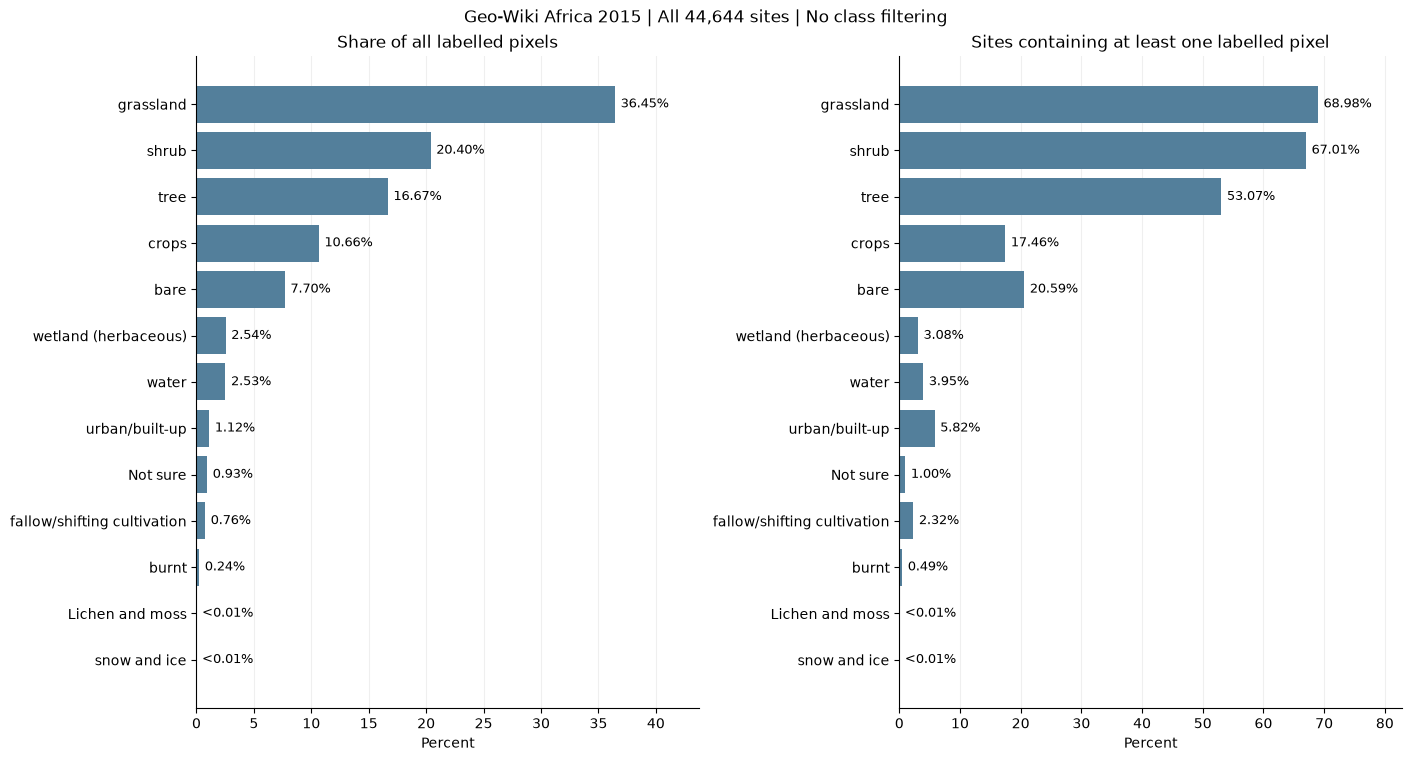

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), layout="constrained")
colors = ["#537f9b" for class_id in class_balance.class_id]
for ax, column, title in zip(
    axes, ["pixel_percent", "site_presence_percent"],
    ["Share of all labelled pixels", "Sites containing at least one labelled pixel"],
):
    values = class_balance[column]
    bars = ax.barh(class_balance.class_name, values, color=colors)
    labels = ["<0.01%" if 0 < value < 0.01 else f"{value:.2f}%" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, max(values.max() * 1.2, 1))
    ax.set_xlabel("Percent")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle(f"Geo-Wiki Africa 2015 | All {len(africa_sites):,} sites | No class filtering")
fig.savefig(figure_dir / "africa_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Conclusions from this run

Generate the numerical conclusion from the executed data instead of copying an
earlier run's totals. Pixel prevalence and spatial presence answer different
questions; the urban comparison below illustrates the difference. Coverage is
uneven and annotations are interpreted reference labels, so these summaries alone
do not establish representative continental prevalence or annotation accuracy.


In [9]:
urban = class_balance.set_index("class_id").loc[URBAN_CLASS_ID]
largest = class_balance.iloc[0]
print(f"Africa: {len(africa_sites):,} sites and {africa_sites.annotations.sum():,} labelled annotation rows.")
print(f"Largest pixel share: {largest.class_name} ({largest.pixel_percent:.2f}%).")
print(f"Urban/built-up: {urban.pixel_percent:.2f}% of labelled pixels; "
      f"present in {int(urban.sites_containing_class):,} sites ({urban.site_presence_percent:.2f}%).")
print(f"Sites departing from 100 annotation rows in Africa: {africa_sites.annotations.ne(100).sum():,}.")
print(f"Summary tables: {table_dir}")
print(f"Figures: {figure_dir}")


Africa: 44,644 sites and 4,464,400 labelled annotation rows.
Largest pixel share: grassland (36.45%).
Urban/built-up: 1.12% of labelled pixels; present in 2,600 sites (5.82%).
Sites departing from 100 annotation rows in Africa: 0.
Summary tables: C:\Users\tomer\OneDrive\Home\MGI\Thesis\tomer_peled_mgi_thesis\runs\tables\geowiki\14871660
Figures: C:\Users\tomer\OneDrive\Home\MGI\Thesis\tomer_peled_mgi_thesis\runs\figures\geowiki\14871660


## 8. Reproduction and limits

From the project root run `pixi run --locked check-geowiki-exploration` after
the download notebook. This executes with a clean kernel and writes a generated
copy to `runs/notebooks/`. Set `REBUILD_SUMMARY=True` for a full CSV rescan;
otherwise the known complete summary is reused. The raw CSV, boundary, summary
CSVs, and lockfile are the persistent inputs needed for offline reproduction.

The summary follows the supplied notebooks' annotation-count semantics. Before
using labels for model training, separately assess unique pixel IDs, conflicting
annotations, label quality, and spatial sampling. No class balancing, raster-grid
reconstruction, TIFF conversion, or QGIS styling is performed by this exploration.
No analytical behavior is promoted into `src/`. These notebooks and environment
changes remain uncommitted; preserve that state alongside the pinned input releases.
